In [77]:
print("Hello! I am learning Python")

Hello! I am learning Python


In [78]:
import os

folder_path = r"C:\project 2-python project"

print(os.listdir(folder_path))

['data_cleaning_steps.py', 'Phase 1 -Product Demand Trend Analysis Report.docx', 'Phase-2 Cleaned Data set.xlsx', 'Phase-2 Data_Cleaning and Data Visualization Explanation steps explained.docx', 'Phase-2 Uncleaned Data set.xlsx', 'Phase-3 Cleaned Retail Dataset-python.xlsx', 'Phase-3 data cleaning-python latest cleaning.ipynb', 'Phase-3 Product Demand Dashboard.pdf', 'Product Demand Dashboard.pdf', 'Product Demand Dashboard.png', 'Product Demand Trend Analysis -ppt.pptx', 'Product Demand Trend Analysis Using Python.docx', 'study purpose - Python_Data_Cleaning_Code_Explanation_Beginner_Guide.pdf', 'using claude Data Cleaning Steps Explained.docx']


In [79]:
import pandas as pd

file_path = r"C:\project 2-python project\Phase-2 Uncleaned Data set.xlsx"

df = pd.read_excel(file_path)

print("Excel file loaded successfully!")

Excel file loaded successfully!


In [80]:
print("Original Dataset Shape:", df.shape)

Original Dataset Shape: (4000, 12)


In [81]:
df = df.dropna(how="all")

print("Rows and columns after removing empty rows:", df.shape)

Rows and columns after removing empty rows: (3900, 12)


In [82]:
df = df.drop_duplicates().reset_index(drop=True)

print("Rows and columns after removing duplicates:", df.shape)

Rows and columns after removing duplicates: (3700, 12)


In [83]:
df = df.rename(columns={
    "Prod ID": "Product_id",
    "Product Name": "Product_name",
    "category": "Category",
    "DATE": "Date",
    "Month Year": "month_year",
    "Units Sold": "units_sold",
    "Unit Price (Rs)": "unit_price",
    "Revenue": "revenue",
    "Stock On Hand": "stock_on_hand",
    "Season": "season",
    "Promo?": "Promotion_flag",
    "Lifecycle Stage": "lifecycle_stage"
})

print(df.columns.tolist())

['Product_id', ' Product Name', 'Category', 'Date', 'month_year', 'units_sold', 'unit_price', 'revenue', 'stock_on_hand', 'Season ', 'Promotion_flag', 'lifecycle_stage']


In [84]:

import re
import pandas as pd

# Function to clean extra spaces
def remove_extra_spaces(value):
    if isinstance(value, str):
        value = re.sub(r"\s+", " ", value).strip()

        # Convert empty or space-only cells into missing values
        if value == "":
            return pd.NA

    return value

# Apply the function to all text columns
for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].apply(remove_extra_spaces)

# Display the result
print("Step 4: Extra Spaces Removed Successfully!")
print("Dataset shape:", df.shape)

print("\nSample cleaned data:")
print(df.head())

# Count remaining missing values
print("\nMissing values in each column:")
print(df.isna().sum())


Step 4: Extra Spaces Removed Successfully!
Dataset shape: (3700, 12)

Sample cleaned data:
  Product_id          Product Name     Category         Date month_year  \
0       P011            Laptop Pro  Electronics   08/12/2025   Dec-2025   
1       P001          Smartphone X  Electronics  10-Feb-2024   Feb-2024   
2       P009  $Steel Water Bottle$         Home   2025-12-05   Dec-2025   
3       P011            Laptop Pro  Electronics   2025-07-18   Jul-2025   
4       P005                   NaN     Footwear   23/03/2025   Mar-2025   

  units_sold unit_price     revenue stock_on_hand        Season   \
0         62      55000     3410000            64         Winter   
1         31      18000      558000            88         Winter   
2         62        450  Rs. 27,900           161         WINTER   
3         60      55000     3300000          65.0        Monsoon   
4         99       3200      316800           151  Summer Season   

  Promotion_flag lifecycle_stage  
0             

In [85]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Standardize column names
df = df.rename(columns={
    "Product_id": "Product id",
    "Product Name": "Product Name",
    "month_year": "Month Year",
    "units_sold": "Units Sold",
    "unit_price": "Unit Price",
    "revenue": "Revenue",
    "stock_on_hand": "Stock On Hand",
    "lifecycle_stage": "Lifecycle Stage"
})

print(df.columns.tolist())

['Product id', 'Product Name', 'Category', 'Date', 'Month Year', 'Units Sold', 'Unit Price', 'Revenue', 'Stock On Hand', 'Season', 'Promotion_flag', 'Lifecycle Stage']


In [86]:

# STEP 5: STANDARDIZE CATEGORIES

# 1. Category mapping
category_mapping = {
    "apparel": "Apparel",
    "aparel": "Apparel",
    "apparels": "Apparel",
    "clothing": "Apparel",

    "appliances": "Appliances",
    "applances": "Appliances",
    "appliance": "Appliances",
    "home appliances": "Appliances",

    "electronic": "Electronics",
    "electronics": "Electronics",

    "foot wear": "Footwear",
    "footwear": "Footwear",
    "footwears": "Footwear",
    "fotwear": "Footwear",

    "home": "Home",
    "hme": "Home",
    "home items": "Home",
    "household": "Home",

    "stationary": "Stationery",
    "stationeries": "Stationery",
    "stationery": "Stationery",
    "stationry": "Stationery",

    "unknown": "Unknown"
}

# 2. Season mapping
Season_mapping = {
    "festiv": "Festive",
    "festival": "Festive",
    "festive": "Festive",
    "festive season": "Festive",

    "monsoon": "Monsoon",
    "monsoon season": "Monsoon",
    "monsun": "Monsoon",
    "rainy": "Monsoon",

    "sumer": "Summer",
    "summer": "Summer",
    "summer season": "Summer",

    "wintr": "Winter",
    "winter": "Winter",
    "winter season": "Winter"
}

# 3. Lifecycle Stage mapping
lifecycle_mapping = {
    "growth": "Growth",
    "grwoth": "Growth",
    "growing": "Growth",

    "maturity": "Maturity",
    "mature": "Maturity",
    "maturty": "Maturity",

    "decline": "Decline",
    "decling": "Decline",
    "declining": "Decline"
}

# 4. Promotion Flag mapping
promotion_mapping = {
    "yes": 1,
    "y": 1,
    "true": 1,
    "no": 0,
    "n": 0,
    "false": 0
}

# Function to standardize values
def standardize_column(series, mapping):
    cleaned = series.map(
        lambda value: value.strip().lower()
        if isinstance(value, str) else value
    )

    mapped = cleaned.map(mapping)

    return mapped.where(mapped.notna(), series)


# Apply mappings
df["Category"] = standardize_column(
    df["Category"], category_mapping
)

df["Season"] = standardize_column(
    df["Season"], Season_mapping
)

df["Lifecycle Stage"] = standardize_column(
    df["Lifecycle Stage"], lifecycle_mapping
)

df["Promotion_flag"] = standardize_column(
    df["Promotion_flag"], promotion_mapping
).astype("Int64")

# Display standardized values
print("STEP 5: STANDARDIZATION COMPLETED")

print("\nDataset shape:", df.shape)

print("\nStandardized Categories:")
print(sorted(df["Category"].dropna().unique()))

print("\nStandardized Seasons:")
print(sorted(df["Season"].dropna().unique()))

print("\nStandardized Lifecycle Stages:")
print(sorted(df["Lifecycle Stage"].dropna().unique()))

print("\nPromotion_flag values:")
print(sorted(df["Promotion_flag"].dropna().astype(str).unique()))


STEP 5: STANDARDIZATION COMPLETED

Dataset shape: (3700, 12)

Standardized Categories:
['Apparel', 'Appliances', 'Elec.', 'Electroncs', 'Electronics', 'Footwear', 'Home', 'Stationery', 'Unknown']

Standardized Seasons:
['Festive', 'Monsoon', 'Summer', 'Winter']

Standardized Lifecycle Stages:
['Decline', 'Growth', 'Maturity']

Promotion_flag values:
['0', '1']


In [87]:

# STEP 6: REMOVE SPECIAL CHARACTERS

# Keep a copy of product names before cleaning
original_names = df["Product Name"].copy()

# Remove special characters from Product Name
df["Product Name"] = (
    df["Product Name"]
    .str.replace(r"[^A-Za-z0-9 ]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Count how many product names were changed
changed_names = (
    original_names.fillna("") != df["Product Name"].fillna("")
).sum()

# Display results
print("STEP 6: SPECIAL CHARACTERS REMOVED SUCCESSFULLY!")

print("\nDataset shape:", df.shape)

print("\nNumber of product names cleaned:", changed_names)

print("\nSample product names after cleaning:")
print(df["Product Name"].dropna().head(15))

print("\nRemaining special characters check:")
print(
    df["Product Name"]
    .dropna()
    .str.contains(r"[^A-Za-z0-9 ]", regex=True)
    .sum()
)


STEP 6: SPECIAL CHARACTERS REMOVED SUCCESSFULLY!

Dataset shape: (3700, 12)

Number of product names cleaned: 243

Sample product names after cleaning:
0             Laptop Pro
1           Smartphone X
2     Steel Water Bottle
3             Laptop Pro
5              Rain Coat
6          Notebook Pack
7            Smart Watch
8              Table Fan
9              Rain Coat
10            DVD Player
11             Rain Coat
12     Bluetooth Speaker
13          Smartphone X
14         Mixer Grinder
15         Winter Jacket
Name: Product Name, dtype: str

Remaining special characters check:
0


In [88]:

# STEP 7: CONVERT DATE FORMAT

# Convert different date formats into one standard format
df["Date"] = pd.to_datetime(
    df["Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)
print(df["Date"].dt.strftime("%Y-%m-%d").head(15))
# Display results
print("STEP 7: DATE FORMAT CONVERSION COMPLETED!")

print("\nDataset shape:", df.shape)

print("\nSample converted dates:")
print(df["Date"].head(15))

# Check the date data type
print("\nDate column data type:")
print(df["Date"].dtype)

# Check for dates that could not be converted
print("\nMissing or unreadable dates:")
print(df["Date"].isna().sum())

# Display the date range
print("\nEarliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())


0     2025-12-08
1     2024-02-10
2     2025-05-12
3     2025-07-18
4     2025-03-23
5     2023-01-29
6     2025-07-27
7     2025-10-17
8     2025-10-19
9     2024-11-05
10    2023-05-24
11    2023-08-07
12    2023-12-25
13    2024-06-20
14    2025-04-08
Name: Date, dtype: str
STEP 7: DATE FORMAT CONVERSION COMPLETED!

Dataset shape: (3700, 12)

Sample converted dates:
0    2025-12-08
1    2024-02-10
2    2025-05-12
3    2025-07-18
4    2025-03-23
5    2023-01-29
6    2025-07-27
7    2025-10-17
8    2025-10-19
9    2024-11-05
10   2023-05-24
11   2023-08-07
12   2023-12-25
13   2024-06-20
14   2025-04-08
Name: Date, dtype: datetime64[us]

Date column data type:
datetime64[us]

Missing or unreadable dates:
0

Earliest date: 2023-01-01 00:00:00
Latest date: 2025-12-31 00:00:00


In [89]:

import pandas as pd
import numpy as np

# STEP 8: REPLACE INVALID VALUES

# 1. Identify invalid text values
INVALID_TOKENS = ["n/a", "unknown", "--", "?", "null"]

text_columns = ["Product Name", "Month Year"]

invalid_text_count = 0

for col in text_columns:
    is_invalid = df[col].map(
        lambda value: isinstance(value, str)
        and value.strip().lower() in INVALID_TOKENS
    )

    invalid_text_count += is_invalid.sum()
    df[col] = df[col].mask(is_invalid, np.nan)


# 2. Convert text numbers temporarily for checking
def to_number(series):
    found = series.astype("string").str.extract(
        r"(-?\d[\d,]*\.?\d*)"
    )[0]

    return pd.to_numeric(
        found.str.replace(",", "", regex=False),
        errors="coerce"
    )


# 3. Replace negative numbers and zero prices
numeric_columns = [
    "Units Sold",
    "Unit Price",
    "Revenue",
    "Stock On Hand"
]

invalid_number_count = 0

for col in numeric_columns:
    numbers = to_number(df[col])

    invalid = numbers < 0

    # Zero unit price is invalid
    if col == "Unit Price":
        invalid = invalid | (numbers == 0)

    invalid_number_count += invalid.sum()
    df.loc[invalid, col] = np.nan


# 4. Display cleaning results
print("STEP 8: INVALID VALUES REPLACED SUCCESSFULLY!")

print("\nDataset shape:", df.shape)

print("\nInvalid text values replaced:", invalid_text_count)
print("Invalid numeric values replaced:", invalid_number_count)

print(
    "Total invalid entries replaced:",
    invalid_text_count + invalid_number_count
)


# 5. Display missing values report
missing_report = df.isna().sum().reset_index()

missing_report.columns = [
    "Column Name",
    "Missing Value Count"
]

print("\nMISSING VALUES REPORT:")
print(missing_report.to_string(index=False))


# 6. Display sample data
print("\nSAMPLE DATA AFTER STEP 8:")

print(
    df.head(10)
    .fillna("Missing Value")
    .to_string(index=False)
)


STEP 8: INVALID VALUES REPLACED SUCCESSFULLY!

Dataset shape: (3700, 12)

Invalid text values replaced: 0
Invalid numeric values replaced: 189
Total invalid entries replaced: 189

MISSING VALUES REPORT:
    Column Name  Missing Value Count
     Product id                    0
   Product Name                   73
       Category                  141
           Date                    0
     Month Year                  210
     Units Sold                  267
     Unit Price                  246
        Revenue                  226
  Stock On Hand                  267
         Season                  108
 Promotion_flag                  163
Lifecycle Stage                  115

SAMPLE DATA AFTER STEP 8:
Product id       Product Name    Category       Date Month Year Units Sold Unit Price       Revenue Stock On Hand  Season  Promotion_flag Lifecycle Stage
      P011         Laptop Pro Electronics 2025-12-08   Dec-2025         62      55000       3410000            64  Winter              

In [90]:


# STEP 9: CHANGE DATA TYPES

import pandas as pd
import numpy as np

# Remove unwanted spaces from column names
df.columns = df.columns.str.strip()

# Function to extract numbers from text
def convert_to_number(series):
    found = series.astype("string").str.extract(
        r"(-?\d[\d,]*\.?\d*)"
    )[0]

    found = found.str.replace(",", "", regex=False)

    return pd.to_numeric(found, errors="coerce")


# 1. Convert whole-number columns
whole_number_columns = [
    "Units Sold",
    "Stock On Hand",
    "Promotion_flag"
]

for col in whole_number_columns:
    if col in df.columns:
        df[col] = convert_to_number(df[col]).round().astype("Int64")
    else:
        print("Column not found:", col)


# 2. Convert decimal-number columns
decimal_columns = [
    "Unit Price",
    "Revenue"
]

for col in decimal_columns:
    if col in df.columns:
        df[col] = convert_to_number(df[col]).astype("float64")
    else:
        print("Column not found:", col)


# 3. Convert text columns
text_columns = [
    "Product Id",
    "Product Name",
    "Category",
    "Month Year",
    "Season",
    "Lifecycle Stage"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype("string")
    else:
        print("Text column skipped:", col)


# 4. Display results
print("\nSTEP 9: DATA TYPES CHANGED SUCCESSFULLY!")

print("\nDataset shape:", df.shape)

print("\nUPDATED DATA TYPES:")
print(df.dtypes)

print("\nSAMPLE DATA AFTER STEP 9:")
print(df.head(10).fillna("Missing Value").to_string(index=False))

print("\nPROMOTION FLAG VALUES:")
if "Promotion_flag" in df.columns:
    print(sorted(df["Promotion_flag"].dropna().unique().tolist()))

print("\nMISSING VALUES IN EACH COLUMN:")
print(df.isna().sum())
# Correct Month Year using Date column
df["Month Year"] = df["Date"].dt.strftime("%b-%Y")

# Verify Date and Month Year
print("\nDate and Month Year Verification:")
print(df[["Date", "Month Year", "Season"]].head(20).to_string(index=False))


Text column skipped: Product Id

STEP 9: DATA TYPES CHANGED SUCCESSFULLY!

Dataset shape: (3700, 12)

UPDATED DATA TYPES:
Product id                    str
Product Name               string
Category                   string
Date               datetime64[us]
Month Year                 string
Units Sold                  Int64
Unit Price                float64
Revenue                   float64
Stock On Hand               Int64
Season                     string
Promotion_flag              Int64
Lifecycle Stage            string
dtype: object

SAMPLE DATA AFTER STEP 9:
Product id       Product Name    Category       Date Month Year  Units Sold  Unit Price       Revenue  Stock On Hand  Season  Promotion_flag Lifecycle Stage
      P011         Laptop Pro Electronics 2025-12-08   Dec-2025          62     55000.0     3410000.0             64  Winter               0          Growth
      P001       Smartphone X Electronics 2024-02-10   Feb-2024          31     18000.0      558000.0             8

In [91]:




import pandas as pd
import numpy as np
import re

# ==========================================
# STEP 10: HANDLE MISSING VALUES
# ==========================================

# 1. Standardize column names
df.columns = [
    re.sub(r"\s+", " ", str(col).strip().replace("_", " "))
    for col in df.columns
]

# 2. Identify important columns
def find_column(name):
    for col in df.columns:
        if col.lower().replace(" ", "") == name.lower().replace(" ", ""):
            return col
    return None

product_col = find_column("Product Id")
promotion_col = find_column("Promotion Flag")

print("Product column:", product_col)
print("Promotion column:", promotion_col)


# 3. Fill missing text values
def fill_text_column(column):

    if column not in df.columns:
        return

    if product_col is not None:
        product_mode = df.groupby(
            product_col, dropna=False
        )[column].transform(
            lambda x: x.mode().iloc[0]
            if not x.mode().empty else np.nan
        )

        df[column] = df[column].fillna(product_mode)

    overall_mode = df[column].mode(dropna=True)

    if not overall_mode.empty:
        df[column] = df[column].fillna(overall_mode.iloc[0])


for column in ["Product Name", "Category", "Lifecycle Stage"]:
    fill_text_column(column)


# 4. Convert Date into datetime format
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(
        df["Date"], errors="coerce"
    )


# 5. Fill Month Year using Date
if "Month Year" in df.columns and "Date" in df.columns:
    df["Month Year"] = df["Month Year"].fillna(
        df["Date"].dt.strftime("%b-%Y")
    )


# 6. Fill Month and Year using Date
if "Month" in df.columns and "Date" in df.columns:
    df["Month"] = df["Month"].fillna(
        df["Date"].dt.strftime("%b")
    )

if "Year" in df.columns and "Date" in df.columns:
    df["Year"] = df["Year"].fillna(
        df["Date"].dt.year
    )


# 7. Fill missing Season values
if "Season" in df.columns:

    if "Date" in df.columns:
        season_data = df.dropna(
            subset=["Date", "Season"]
        ).copy()

        season_data["Month Number"] = (
            season_data["Date"].dt.month
        )

        month_season = season_data.groupby(
            "Month Number"
        )["Season"].agg(
            lambda x: x.mode().iloc[0]
            if not x.mode().empty else np.nan
        ).to_dict()

        df["Season"] = df["Season"].fillna(
            df["Date"].dt.month.map(month_season)
        )

    season_mode = df["Season"].mode(dropna=True)

    if not season_mode.empty:
        df["Season"] = df["Season"].fillna(
            season_mode.iloc[0]
        )


# 8. Fill Promotion Flag with 0
if promotion_col is not None:
    df[promotion_col] = pd.to_numeric(
        df[promotion_col], errors="coerce"
    ).fillna(0).astype("Int64")


# 9. Convert numerical columns to float64
numeric_columns = [
    "Unit Price",
    "Revenue",
    "Units Sold",
    "Stock On Hand"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).astype("float64")


# 10. Fill numerical missing values using product-wise median
def fill_numeric_column(column):

    if column not in df.columns:
        return

    if product_col is not None:
        product_median = df.groupby(
            product_col, dropna=False
        )[column].transform("median")

        df[column] = df[column].fillna(product_median)

    overall_median = df[column].median()

    if pd.notna(overall_median):
        df[column] = df[column].fillna(overall_median)


# 11. Fill Unit Price
fill_numeric_column("Unit Price")


# 12. Fill Units Sold using Revenue and Unit Price
if all(col in df.columns for col in ["Revenue", "Unit Price", "Units Sold"]):

    calculated_units = (
        df["Revenue"] / df["Unit Price"]
    ).replace([np.inf, -np.inf], np.nan)

    df["Units Sold"] = df["Units Sold"].fillna(
        calculated_units.round()
    )

fill_numeric_column("Units Sold")


# 13. Fill Stock On Hand
fill_numeric_column("Stock On Hand")


# 14. Fill Revenue using Units Sold × Unit Price
if all(col in df.columns for col in ["Revenue", "Units Sold", "Unit Price"]):

    calculated_revenue = (
        df["Units Sold"] * df["Unit Price"]
    )

    df["Revenue"] = df["Revenue"].fillna(
        calculated_revenue
    )

fill_numeric_column("Revenue")


# 15. Convert whole-number columns back to integers
for col in ["Units Sold", "Stock On Hand"]:
    if col in df.columns:
        df[col] = df[col].round().astype("Int64")


# ==========================================
# 16. DISPLAY RESULTS
# ==========================================

print("\n========================================")
print("STEP 10: MISSING VALUES HANDLED!")
print("========================================")

print("\n1. Dataset Shape:")
print(df.shape)

print("\n2. Total Rows:")
print(df.shape[0])

print("\n3. Total Columns:")
print(df.shape[1])

print("\n4. Missing Values in Each Column:")
print(df.isna().sum())

print("\n5. Total Missing Cells Remaining:")
print(df.isna().sum().sum())

print("\n6. Data Types:")
print(df.dtypes)

print("\n7. Sample Data After Step 10:")
print(
    df.head(10).astype("string")
    .fillna("Missing Value")
    .to_string(index=False)
)
# Check Date, Month Year and Season consistency
print(df[["Date", "Month Year", "Season"]].head(20).to_string(index=False))

print("\n========================================")
print("STEP 10 COMPLETED SUCCESSFULLY!")
print("========================================")


Product column: Product id
Promotion column: Promotion flag

STEP 10: MISSING VALUES HANDLED!

1. Dataset Shape:
(3700, 12)

2. Total Rows:
3700

3. Total Columns:
12

4. Missing Values in Each Column:
Product id         0
Product Name       0
Category           0
Date               0
Month Year         0
Units Sold         0
Unit Price         0
Revenue            0
Stock On Hand      0
Season             0
Promotion flag     0
Lifecycle Stage    0
dtype: int64

5. Total Missing Cells Remaining:
0

6. Data Types:
Product id                    str
Product Name               string
Category                   string
Date               datetime64[us]
Month Year                    str
Units Sold                  Int64
Unit Price                float64
Revenue                   float64
Stock On Hand               Int64
Season                     string
Promotion flag              Int64
Lifecycle Stage            string
dtype: object

7. Sample Data After Step 10:
Product id       Product Na

In [92]:


import pandas as pd
import numpy as np

# STEP 11: HANDLE OUTLIERS

# Identify the actual Product ID column
product_col = next(
    col for col in df.columns
    if col.strip().lower() == "product id"
)

# Calculate Q1 (25th percentile) for each product
q1 = df.groupby(product_col)["Units Sold"].transform(
    lambda values: values.quantile(0.25)
)

# Calculate Q3 (75th percentile) for each product
q3 = df.groupby(product_col)["Units Sold"].transform(
    lambda values: values.quantile(0.75)
)

# Calculate IQR
iqr = q3 - q1

# Calculate upper limit
upper_limit = q3 + (3 * iqr)

# Count extreme values before capping
outliers_count = (df["Units Sold"] > upper_limit).sum()

# Cap extreme Units Sold values
df["Units Sold"] = np.minimum(
    df["Units Sold"].astype(float),
    upper_limit
).round().astype("Int64")

# Recalculate Revenue
df["Revenue"] = (
    df["Units Sold"].astype(float) * df["Unit Price"]
)

# Display results
print("=" * 45)
print("STEP 11: OUTLIERS HANDLED SUCCESSFULLY!")
print("=" * 45)

print("\nDataset shape:", df.shape)
print("\nNumber of outliers capped:", outliers_count)

print("\nSample data after Step 11:")
print(df.head(10).to_string(index=False))

print("\nMissing values remaining:", df.isna().sum().sum())

print("\nDuplicate rows remaining:", df.duplicated().sum())

print("\nUpdated data types:")
print(df.dtypes)


STEP 11: OUTLIERS HANDLED SUCCESSFULLY!

Dataset shape: (3700, 12)

Number of outliers capped: 73

Sample data after Step 11:
Product id       Product Name    Category       Date Month Year  Units Sold  Unit Price   Revenue  Stock On Hand  Season  Promotion flag Lifecycle Stage
      P011         Laptop Pro Electronics 2025-12-08   Dec-2025          62     55000.0 3410000.0             64  Winter               0          Growth
      P001       Smartphone X Electronics 2024-02-10   Feb-2024          31     18000.0  558000.0             88  Winter               0          Growth
      P009 Steel Water Bottle        Home 2025-05-12   May-2025          62       450.0   27900.0            161  Winter               0        Maturity
      P011         Laptop Pro Electronics 2025-07-18   Jul-2025          60     55000.0 3300000.0             65 Monsoon               0          Growth
      P005      Running Shoes    Footwear 2025-03-23   Mar-2025          99      3200.0  316800.0            

In [93]:


# STEP 12: SPLIT COLUMNS

# Find the Month Year column safely
month_year_col = next(
    (col for col in df.columns
     if col.strip().lower().replace("_", " ") == "month year"),
    None
)

if month_year_col is None:
    print("ERROR: Month Year column not found.")
    print("Available columns:", df.columns.tolist())

else:
    # Split Month Year into Month and Year
    parts = df[month_year_col].astype("string").str.split(
        "-", n=1, expand=True
    )

    df["Month"] = parts[0].astype("string")

    df["Year"] = pd.to_numeric(
        parts[1], errors="coerce"
    ).astype("Int64")

    # Remove original Month Year column
    df = df.drop(columns=[month_year_col])

    # Display final results
    print("=" * 45)
    print("STEP 12: COLUMNS SPLIT SUCCESSFULLY!")
    print("=" * 45)

    print("\nDataset shape:", df.shape)

    print("\nFinal column names:")
    print(df.columns.tolist())

    print("\nMissing values in each column:")
    print(df.isna().sum())

    print("\nTotal missing cells remaining:", df.isna().sum().sum())

    print("\nDuplicate rows remaining:", df.duplicated().sum())

    print("\nSample final data:")
    print(df.head(10).to_string(index=False))

    print("\nFinal data types:")
    print(df.dtypes)


STEP 12: COLUMNS SPLIT SUCCESSFULLY!

Dataset shape: (3700, 13)

Final column names:
['Product id', 'Product Name', 'Category', 'Date', 'Units Sold', 'Unit Price', 'Revenue', 'Stock On Hand', 'Season', 'Promotion flag', 'Lifecycle Stage', 'Month', 'Year']

Missing values in each column:
Product id         0
Product Name       0
Category           0
Date               0
Units Sold         0
Unit Price         0
Revenue            0
Stock On Hand      0
Season             0
Promotion flag     0
Lifecycle Stage    0
Month              0
Year               0
dtype: int64

Total missing cells remaining: 0

Duplicate rows remaining: 0

Sample final data:
Product id       Product Name    Category       Date  Units Sold  Unit Price   Revenue  Stock On Hand  Season  Promotion flag Lifecycle Stage Month  Year
      P011         Laptop Pro Electronics 2025-12-08          62     55000.0 3410000.0             64  Winter               0          Growth   Dec  2025
      P001       Smartphone X Elect

In [94]:

# CORRECT MONTH AND YEAR USING THE DATE COLUMN

# Extract Month from Date
df["Month"] = df["Date"].dt.strftime("%b")

# Extract Year from Date
df["Year"] = df["Date"].dt.year.astype("Int64")

# Verify the corrected values
print("MONTH AND YEAR CORRECTED SUCCESSFULLY!")

print("\nUpdated sample data:")
print(
    df[["Date", "Month", "Year"]]
    .head(10)
    .to_string(index=False)
)

print("\nDataset shape:", df.shape)

print("\nMissing values:")
print(df[["Date", "Month", "Year"]].isna().sum())


MONTH AND YEAR CORRECTED SUCCESSFULLY!

Updated sample data:
      Date Month  Year
2025-12-08   Dec  2025
2024-02-10   Feb  2024
2025-05-12   May  2025
2025-07-18   Jul  2025
2025-03-23   Mar  2025
2023-01-29   Jan  2023
2025-07-27   Jul  2025
2025-10-17   Oct  2025
2025-10-19   Oct  2025
2024-11-05   Nov  2024

Dataset shape: (3700, 13)

Missing values:
Date     0
Month    0
Year     0
dtype: int64


In [95]:
import os

# Automatically find Desktop location
desktop_path = os.path.join(os.path.expanduser("~"), "Desktop")

output_path = os.path.join(
    desktop_path,
    "Cleaned Retail Dataset.xlsx"
)

df.to_excel(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path)

Cleaned dataset saved successfully!
File location: C:\Users\Edward\Desktop\Cleaned Retail Dataset.xlsx


In [2]:
import pandas as pd

import os

desktop_path = os.path.join(
    os.path.expanduser("~"), "Desktop"
)

file_path = os.path.join(
    desktop_path,
    "Cleaned Retail Dataset.xlsx"
)

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (3700, 13)
['Product id', 'Product Name', 'Category', 'Date', 'Units Sold', 'Unit Price', 'Revenue', 'Stock On Hand', 'Season', 'Promotion flag', 'Lifecycle Stage', 'Month', 'Year']


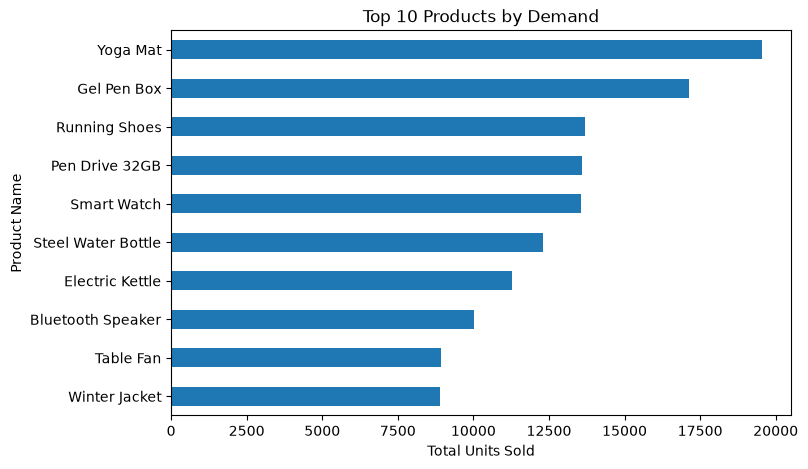

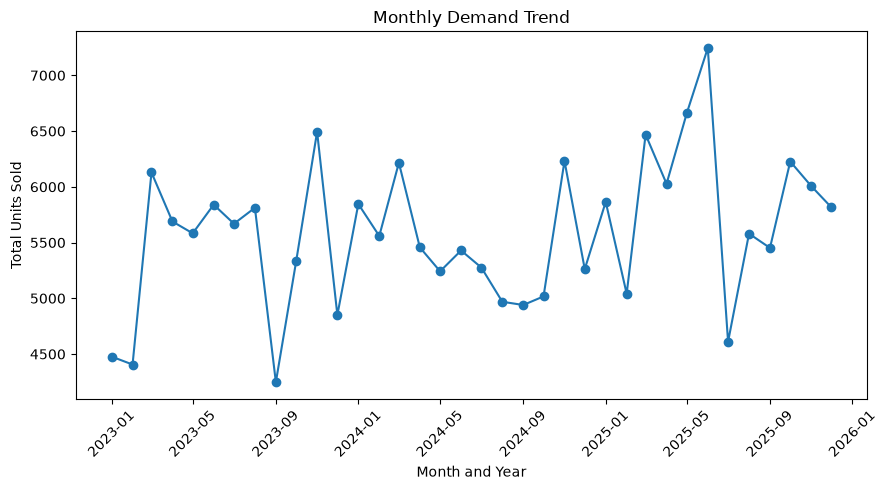

In [96]:

import matplotlib.pyplot as plt

# Chart 1: Product-wise Demand
product_sales = df.groupby("Product Name")["Units Sold"].sum()
product_sales = product_sales.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
product_sales.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Demand")
plt.xlabel("Total Units Sold")
plt.ylabel("Product Name")
plt.show()


# Chart 2: Monthly Demand Trend
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Units Sold"].sum()

monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(9, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Demand Trend")
plt.xlabel("Month and Year")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [4]:
import os
import pandas as pd
from openpyxl import load_workbook
from openpyxl.drawing.image import Image

# Desktop path
desktop_path = os.path.join(
    os.path.expanduser("~"), "Desktop"
)

output_path = os.path.join(
    desktop_path,
    "Cleaned Retail Dataset Final.xlsx"
)

# Save cleaned dataset in Sheet 1
with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    df.to_excel(
        writer,
        sheet_name="Cleaned Dataset",
        index=False
    )

# Open the Excel workbook
workbook = load_workbook(output_path)

# Create Sheet 2
chart_sheet = workbook.create_sheet("Charts")

# Insert existing chart images
image1 = Image(os.path.join(desktop_path, "chart1.png"))
image1.width = 650
image1.height = 350
chart_sheet.add_image(image1, "A1")

image2 = Image(os.path.join(desktop_path, "chart2.png"))
image2.width = 650
image2.height = 350
chart_sheet.add_image(image2, "A22")

# Save workbook
workbook.save(output_path)

print("Excel file saved successfully!")
print("Location:", output_path)

Excel file saved successfully!
Location: C:\Users\Edward\Desktop\Cleaned Retail Dataset Final.xlsx
